# Beyond the standard GLM
## Environmental Statistics 4
C.F. Dormann

There are two thing to learn today:
• Using other implementations of GLMs.
• Using optimisation to define and run your own GLM-like analysis.

## 1 Exercise 1: Negative binomial regression
The response variable of interest is days absent, daysabs. The variable math is the standardized math score
for each student. The variable prog is a three-level nominal variable indicating the type of instructional
program in which the student is enrolled.

### 1.1 Load the data and look at the summary of it

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import arviz as az
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
from scipy.optimize import curve_fit
from tabulate import tabulate
from scipy.stats import t
from scipy.stats import norm
import warnings

import os
os.environ["R_HOME"] = r"C:\Users\ia1015\.conda\envs\envstats2\lib\R"

In [2]:
absent = pd.read_spss("nb_data.sav")
print(absent.describe(include="all"))

                 id  gender        math     daysabs        prog
count    314.000000     314  314.000000  314.000000  314.000000
unique          NaN       2         NaN         NaN         NaN
top             NaN  female         NaN         NaN         NaN
freq            NaN     160         NaN         NaN         NaN
mean    1575.910828     NaN   48.267516    5.955414    2.213376
std      502.314832     NaN   25.362391    7.036958    0.651133
min     1001.000000     NaN    1.000000    0.000000    1.000000
25%     1079.250000     NaN   28.000000    1.000000    2.000000
50%     1158.500000     NaN   48.000000    4.000000    2.000000
75%     2077.750000     NaN   70.000000    8.000000    3.000000
max     2157.000000     NaN   99.000000   35.000000    3.000000


In [3]:
# two columns need conversion to factors:
absent["gender"] = absent["gender"].map({1: "female", 2: "male"}).astype("category")
absent["prog"] = absent["prog"].astype("category")

print(absent.describe())

                id        math     daysabs
count   314.000000  314.000000  314.000000
mean   1575.910828   48.267516    5.955414
std     502.314832   25.362391    7.036958
min    1001.000000    1.000000    0.000000
25%    1079.250000   28.000000    1.000000
50%    1158.500000   48.000000    4.000000
75%    2077.750000   70.000000    8.000000
max    2157.000000   99.000000   35.000000


### 1.2 Plot the data
Plot absence times as a function of math score and program enrolled, ideally next to each other as a "double plot", yet each panel should be **square**!

C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\seaborn\categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


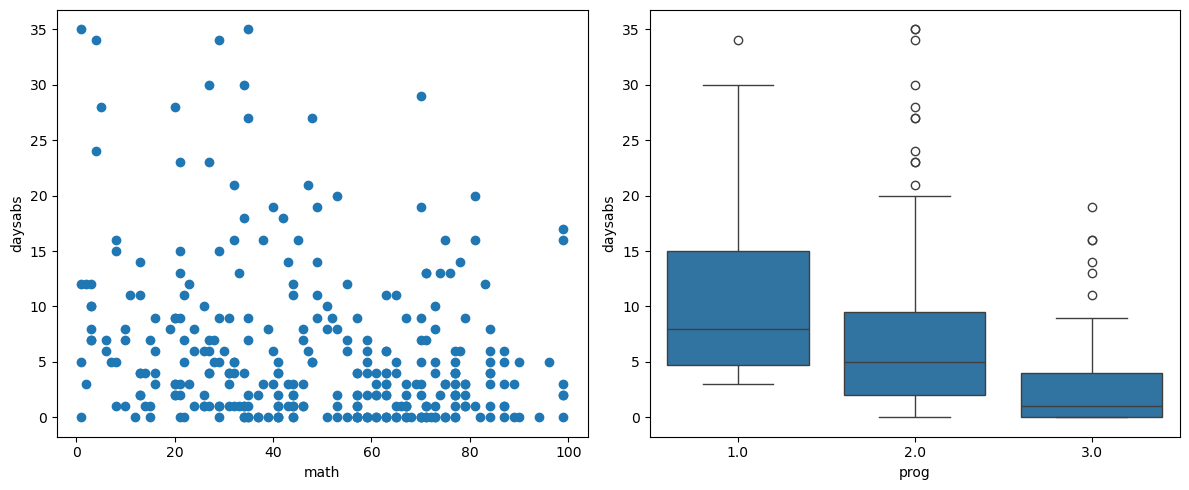

In [4]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(x="math", y="daysabs", data=absent)
plt.xlabel("math")
plt.ylabel("daysabs")

plt.subplot(1, 2, 2)
sns.boxplot(x="prog", y="daysabs", data=absent)
plt.xlabel("prog")
plt.ylabel("daysabs")

plt.tight_layout()
plt.show()


Clearly the data are very skewed.

### 1.3 Fit a Poisson regression model
Use both gender and math and their interaction as predictors.


In [5]:
fp = smf.glm(formula='daysabs ~ math*prog', data=absent, family=sm.families.Poisson()).fit()
print(fp.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                daysabs   No. Observations:                  314
Model:                            GLM   Df Residuals:                      308
Model Family:                 Poisson   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1325.1
Date:                Mon, 03 Nov 2025   Deviance:                       1766.9
Time:                        21:24:26   Pearson chi2:                 2.03e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.7620
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            2.6549      0.083  

In [19]:
# dispersion 
fp.deviance/fp.df_resid

5.7366407572287885

Clearly, the dispersion (residual deviance divided by degrees of freedom) indicates a very poor fit ($\gg 1$). That makes the *p*-values unreliable.


### 1.4 Do the same with a negative binomial model

In [29]:
# first extract alpha

formula='daysabs ~ math*prog'

nb = smf.negativebinomial(formula, data = absent).fit()
alpha=nb.params['alpha']

Optimization terminated successfully.
         Current function value: 2.754412
         Iterations: 30
         Function evaluations: 37
         Gradient evaluations: 37


In [16]:
# using the manual calc way
absent2 = absent.copy() 
absent2['lambda_'] = fp.mu

absent2['ols_dep'] = absent2.apply(lambda x: ((x['daysabs'] - x['lambda_'])**2 - x['lambda_']) / x['lambda_'], axis=1)

ols_expr = """ols_dep ~ lambda_ - 1"""  
    
olsr_results = smf.ols(ols_expr, absent2).fit()
alpha2=olsr_results.params['lambda_']

In [11]:
fnb = smf.glm(formula='daysabs ~ math*prog', data=absent, family=sm.families.NegativeBinomial(alpha=alpha)).fit()
print(fnb.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                daysabs   No. Observations:                  314
Model:                            GLM   Df Residuals:                      308
Model Family:        NegativeBinomial   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -864.89
Date:                Mon, 03 Nov 2025   Deviance:                       358.48
Time:                        21:29:35   Pearson chi2:                     339.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2020
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            2.6650      0.301  

In [24]:
fnb2 = smf.glm(formula='daysabs ~ math*prog', data=absent, family=sm.families.NegativeBinomial(alpha=alpha2)).fit()
print(fnb2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                daysabs   No. Observations:                  314
Model:                            GLM   Df Residuals:                      308
Model Family:        NegativeBinomial   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -866.67
Date:                Mon, 03 Nov 2025   Deviance:                       406.62
Time:                        21:44:58   Pearson chi2:                     395.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2326
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            2.6649      0.275  

In [23]:
# dispersion 
fnb2.deviance/fnb2.df_resid

1.320202389674583

In [25]:
# dispersion 
fnb.deviance/fnb.df_resid

1.1638984009097848

In [27]:
# Calculate R-squared
r_squared = 1 - (fnb2.deviance / fnb2.null_deviance)
print("R-squared is:", r_squared)

R-squared is: 0.169753369327595


The dispersion is now fine, and the p-values have substantially changed, with very little evidence for a substantial effect of the programme enrolled in, and no effect of maths left.

### 1.5 Now do the same with `vglm` from **VGAM** (for R users)
This is not yet implemented in python. So we can call R codes to see the results.

In [31]:
%load_ext rpy2.ipython

C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\rpy2\robjects\packages.py:367: UserWarning: The symbol 'quartz' is not in this R namespace/package.
  warnings.warn(


In [32]:
%%R
suppressWarnings(install.packages("haven"))
library(haven)

--- Please select a CRAN mirror for use in this session ---

  There is a binary version available but the source version is later:
      binary source needs_compilation
haven  2.5.2  2.5.5              TRUE

  Binaries will be installed


R[write to console]: trying URL 'https://mirror.dogado.de/cran/bin/windows/contrib/4.1/haven_2.5.2.zip'

R[write to console]: Content type 'application/zip'
R[write to console]:  length 1324062 bytes (1.3 MB)

R[write to console]: downloaded 1.3 MB




package 'haven' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\ia1015\AppData\Local\Temp\Rtmp8MRrbN\downloaded_packages


In [33]:
%%R
suppressWarnings(install.packages("VGAM"))
library(VGAM)


  There is a binary version available but the source version is later:
     binary source needs_compilation
VGAM  1.1-8 1.1-13              TRUE

  Binaries will be installed


R[write to console]: trying URL 'https://mirror.dogado.de/cran/bin/windows/contrib/4.1/VGAM_1.1-8.zip'

R[write to console]: Content type 'application/zip'
R[write to console]:  length 7510631 bytes (7.2 MB)

R[write to console]: downloaded 7.2 MB




package 'VGAM' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\ia1015\AppData\Local\Temp\Rtmp8MRrbN\downloaded_packages


R[write to console]: Loading required package: stats4

R[write to console]: Loading required package: splines



In [34]:
%%R
absent <- read_sav(file="nb_data.sav")

# two columns need conversion to factors:
absent$gender <- factor(ifelse(absent$gender == 1, "female", "male"))
absent$prog <- factor(absent$prog)

fvnb <- vglm(daysabs ~ math*prog, data=absent, family=negbinomial())
summary(fvnb)


Call:
vglm(formula = daysabs ~ math * prog, family = negbinomial(), 
    data = absent)

Coefficients: 
                Estimate Std. Error z value Pr(>|z|)    
(Intercept):1  2.6650233  0.3007009   8.863  < 2e-16 ***
(Intercept):2  0.0383193  0.1009873   0.379 0.704356    
math          -0.0071254  0.0057080  -1.248 0.211914    
prog2         -0.4229627  0.3402873  -1.243 0.213883    
prog3         -1.6871019  0.4488510  -3.759 0.000171 ***
math:prog2    -0.0004948  0.0065745  -0.075 0.940012    
math:prog3     0.0072151  0.0078394   0.920 0.357383    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Names of linear predictors: loglink(mu), loglink(size)

Log-likelihood: -864.8854 on 621 degrees of freedom

Number of Fisher scoring iterations: 5 

No Hauck-Donner effect found in any of the estimates



In [35]:
%%R
newmath12 <- 1:99
newmath3 <- seq(8, 99, len=101)
preds1 <- predict(fvnb, newdata=data.frame("math"=newmath12, "prog"="1"), se.fit=T)
preds2 <- predict(fvnb, newdata=data.frame("math"=newmath12, "prog"="2"), se.fit=T)
preds3 <- predict(fvnb, newdata=data.frame("math"=newmath3, "prog"="3"), se.fit=T)

In [36]:
%%R

cols <- terrain.colors(4) # we only use 3, but the highest is always rather white
col2rgb(cols) # if we need the rgb values


      [,1] [,2] [,3] [,4]
red      0  230  236  242
green  166  230  177  242
blue     0    0  118  242


In [37]:
%%R

# get range per prog:
with(absent, tapply(math, prog, range))

$`1`
[1]  1 99

$`2`
[1]  1 99

$`3`
[1]  8 99



In [38]:
%%R

newmath12 <- 1:99
newmath3 <- seq(8, 99, len=101)
preds1 <- predict(fvnb, newdata=data.frame("math"=newmath12, "prog"="1"), se.fit=T)

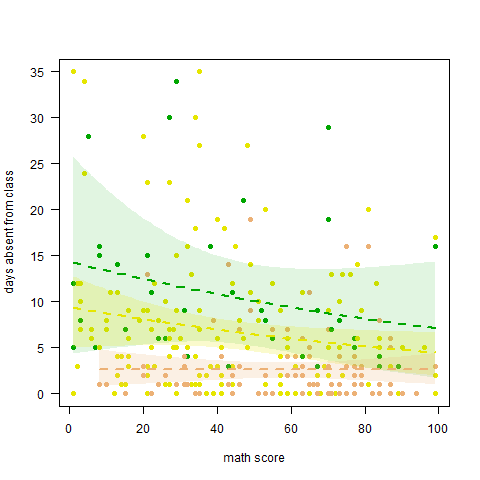

In [39]:
%%R
plot(daysabs ~ math, data=absent, pch=16, col=cols[prog], las=1, xlab="math score", ylab="days absent from class")

lines(newmath12, exp(preds1$fitted.values[,1]), col=cols[1], lwd=2, lty=2)
polygon(c(newmath12, rev(newmath12)), c(exp(preds1$fitted.values[,1] + 2*preds1$se.fit[,1]),
       rev(exp(preds1$fitted.values[,1] -2*+ 2*preds1$se.fit[,1]))),
       border=NA, col=rgb(0, 166, 0, 30, maxColorValue=255))

preds2 <- predict(fvnb, newdata=data.frame("math"=newmath12, "prog"="2"), se.fit=T)
lines(newmath12, exp(preds2$fitted.values[,1]), col=cols[2], lwd=2, lty=2)
polygon(c(newmath12, rev(newmath12)), c(exp(preds2$fitted.values[,1] + 2*preds2$se.fit[,1]),
       rev(exp(preds2$fitted.values[,1] -2*+ 2*preds2$se.fit[,1]))),
       border=NA, col=rgb(230, 230, 0, 50, maxColorValue=255))

preds3 <- predict(fvnb, newdata=data.frame("math"=newmath3, "prog"="3"), se.fit=T)
lines(newmath3, exp(preds3$fitted.values[,1]), col=cols[3], lwd=2, lty=2)
polygon(c(newmath3, rev(newmath3)), c(exp(preds3$fitted.values[,1] + 2*preds3$se.fit[,1]),
        rev(exp(preds3$fitted.values[,1] -2*+ 2*preds3$se.fit[,1]))),
        border=NA, col=rgb(236, 177, 118, 50, maxColorValue=255))

The estimates are identical for `smf.glm` and `vglm`, as they should be. 

###  1.6 Plot fitted regression
Finally, plot the data again, indicating by three different colours the three program levels (1-3). Then compute the fitted 3 (plus errors!) lines from the negative binomial and add them to the plot.

Ideally, you would restrict the range of the predicted regression to the range of the data *for that program*. 

Finally, it is customary to indicate non-significant lines (i.e. all of them) as dashed rather than solid lines.

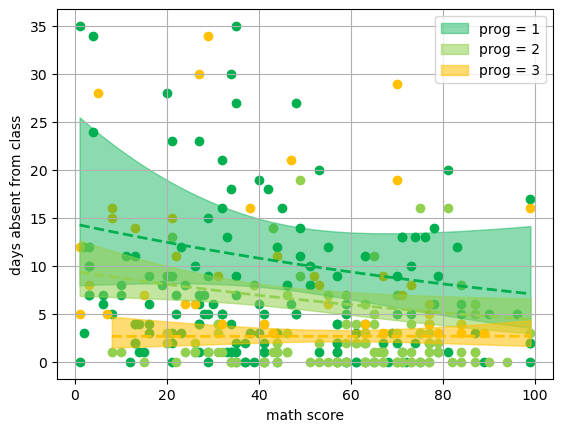

In [60]:
for i, category in enumerate(absent["prog"].unique()):
    plt.scatter(
        absent.loc[absent["prog"] == category, "math"],
        absent.loc[absent["prog"] == category, "daysabs"],
        color=cols[i],
        marker="o",
    )

# Prog = 1
plt.plot(newmath1, preds1["mean"], color="#00B050", linewidth=2, linestyle="--") #
plt.fill_between(newmath1, preds1["mean_ci_upper"], preds1["mean_ci_lower"],
                 color="#00B050",alpha=0.45, label = "prog = 1")

# Prog = 2
plt.plot(newmath2, preds2["mean"], color="#92D050", linewidth=2, linestyle="--") #
plt.fill_between(newmath2, preds2["mean_ci_upper"], preds2["mean_ci_lower"],
                 color="#92D050", alpha=0.55, label = "prog = 2")

# Prog = 3
plt.plot(newmath3, preds3["mean"],color="#FFC000", linewidth=2, linestyle="--") # 
plt.fill_between(newmath3, preds3["mean_ci_upper"], preds3["mean_ci_lower"],
                 color="#FFC000",alpha=0.55, label = "prog = 3")

plt.xlabel("math score")
plt.ylabel("days absent from class")
plt.legend()
plt.grid(True)
plt.show()

The figure illustrates that `prog3` is different, and the negative estimate is reflected by the overall lower predicted values.

Note that despite the (negative) exponential form of the line, they appear almost linear, as the slope is really low.


## 2 Exercise 2: Optimising a likelihood-based model
Fit a non-linear function to data. For a change, we invent data representing a noisy sine-wave, so that we can directly evaluate whether our optimiser actually worked and estimated the values correctly.

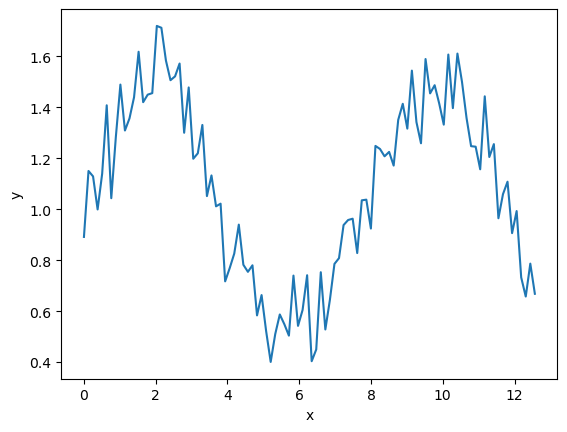

In [79]:
x = np.linspace(0, 4 * np.pi, num=100)
np.random.seed(123)
y = 1 + 0.5 * np.sin(0.8 * x) + np.random.normal(0, scale=0.1, size=100)

plt.plot(x, y, '-')
plt.xlabel("x")
plt.ylabel("y")
plt.show()


### 2.1 Fitting a non-linear regression by hand
First formulate a function to optimise, including the assumption of (1) which distribution the data are from, and (2) the parameters to be fitted.

In [65]:
def sinefun(params):
    a, b, c, log_s = params
    s = np.exp(log_s)
    yhat = a + b * np.sin(c * x)
    return np.sum(norm.logpdf(y, loc=yhat, scale=s))

# Example call
params_init = np.array([1, 1, 1, 1])
sinefun(params_init)

-195.06029123082712

In [66]:
# manual calculation of the likelihood : 
def sinefun2(params):
    a, b, c, log_s = params
    s = np.exp(log_s)
    yhat = a + b * np.sin(c * x)
    return np.sum(-np.log(s) - 0.5 * np.log(2 * np.pi) - 0.5 * ((y - yhat) / s)**2)


params_init = np.array([1, 1, 1, 1])
sinefun2(params_init) 

-195.06029123082712

A few things are worth remembering:

  * as the standard deviation *must* be positive, we use the exponential transformation to ensure this;
  * this function yields the log-likelihood of observing the data *y*, given the parameters a to s; we want to *maximise* this value during optimisation;
  * `yhat` is the estimated value computed by our non-normal function.
 

In [73]:
# NOTE: maximze (log-likelihood) = minimize -(log-likelihood)
# Since we want to maximize, we have to return -(log-likelihood) in our function
def sinefun(params):
    a, b, c, log_s = params
    s = np.exp(log_s)
    yhat = a + b * np.sin(c * x)
    loglikelihood = np.sum(norm.logpdf(y, loc=yhat, scale=s)) # Return negative log-likelihood for minimization
    return -loglikelihood

optim = minimize(sinefun, params_init, method='BFGS', hess=True)

a_opt, b_opt, c_opt, log_s_opt = optim.x
s_opt = np.exp(log_s_opt)

# Print the optimized parameter values and negative log-likelihood
print("Optimized Parameters:")
print("a:", a_opt)
print("b:", b_opt)
print("c:", c_opt)
print("s:", s_opt)
print("log(s):", log_s_opt)
print("")

print("Negative Log-Likelihood:", optim.fun)
print("")

# The default is the inverse Hessian matrix, so we invert it to get the one we want
print("Hessian Matrix:")
print(np.linalg.inv(optim.hess_inv))

print("")
print("Convergence Message:", optim.message)


Optimized Parameters:
a: 1.0068357524323195
b: 0.49053437209742484
c: 0.8049143773294921
s: 0.11191663867559216
log(s): -2.19000098235333

Negative Log-Likelihood: -77.10624580220811

Hessian Matrix:
[[ 7.97806364e+03  1.24720218e+03 -4.51335733e+03 -1.79177075e+01]
 [ 1.24720218e+03  3.62671832e+03 -2.04755155e+02 -1.08922819e+02]
 [-4.51335733e+03 -2.04755155e+02  5.93112816e+04 -5.14730946e+02]
 [-1.79177075e+01 -1.08922819e+02 -5.14730946e+02  1.98573543e+02]]

Convergence Message: Optimization terminated successfully.


C:\Users\ia1015\AppData\Local\Temp\ipykernel_6212\2116508617.py:9: RuntimeWarning: Method BFGS does not use Hessian information (hess).
  optim = minimize(sinefun, params_init, method='BFGS', hess=True)


The `minimize` function by default minimises, hence we need to change the sign of the sinefun function

The optimiser algorithm is a matter of experience and taste. The default, Nelder-Mead, is non-parametric, while BFGS is a quasi-Newton approach, which should be faster but less robust.

The key point to look out for the message that `Optimization terminated successfully`. Everything else means the optimisation failed.

Now, the estimates are very close to the true values (1, 0.5, 0.8 and 0.1). The last value needs to be back-transformed from `exp(-2.19) = 0.11`.

And finally, we have asked for the Hessian, which we can use to compute standard errors for our estimates:

In [74]:
se = np.sqrt(np.diag(op.hess_inv))

print("Standard Errors:")
print("a:", se[0])
print("b:", se[1])
print("c:", se[2])
print("s:", se[3])


Standard Errors:
a: 0.011773436906835683
b: 0.017215444549062035
c: 0.004250280976488094
s: 0.07241924092231874


Now we plot the fitted on the data

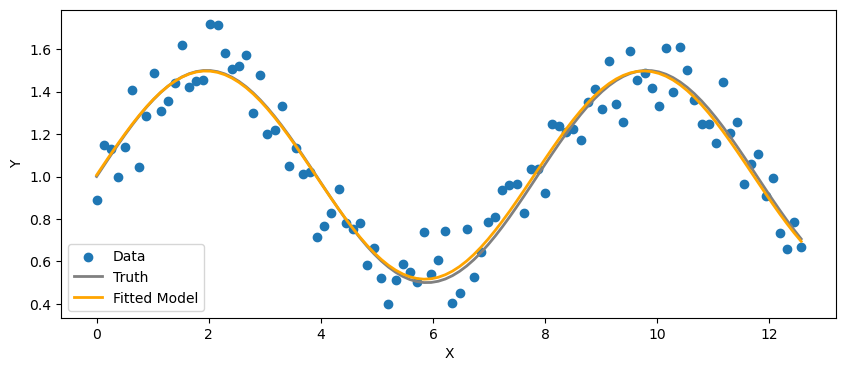

In [77]:
# Plotting the data (x, y)
plt.figure(figsize=(10,4))
plt.scatter(x, y, label='Data')

# Truth curve
plt.plot(x, 1 + 0.5 * np.sin(0.8 * x), label='Truth', color='grey',
linewidth=2)

# Curve using parameters from op$par
plt.plot(x, a_opt + b_opt * np.sin(c_opt * x), label='Fitted Model',
color='orange', linewidth=2)

# Customize the plot
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

### 2.2 Non-linear least squares
In this case, with a normally distributed error,`Python` has a simpler function at its disposal `curve_fit`. Fit the fucntion using `curve_fit`; are the results similar to the optimization approach in the previous section?

In [80]:
# Define the model function

def model(x, a, b, c):
    return a + b * np.sin(c * x)

# Initial guesses for parameters 
initial_guess = [1, 1, 1]

# Fit the model
params, covariance = curve_fit(model, x, y, p0=initial_guess)

# params contains the fitted a, b, c
a_fit, b_fit, c_fit = params
print("Fitted parameters:", params)

# Optional: get standard errors
standard_errors = np.sqrt(np.diag(covariance))
print("Standard errors:", standard_errors)

Fitted parameters: [1.00683577 0.49053437 0.8049144 ]
Standard errors: [0.01195726 0.01706829 0.00428658]


In [83]:
# if you want a summary table with pvalue, do it manaully

# Calculate t-statistics
t_values = params / standard_errors

# degrees of freedom
df = len(y) - len(params)  

# Calculate p-values from t-statistics
p_values = 2 * (1 - t.cdf(np.abs(t_values), df))

# Create a summary DataFrame
summary_df = pd.DataFrame({
    'Param': ['a', 'b', 'c'],
    'Estimate': params,
    'Std. Error': standard_errors,
    't-value': t_values,
    'Pr(>|t|)': p_values,
    'Lower CI': params - 1.96 * standard_errors,
    'Upper CI': params + 1.96 * standard_errors
})

print(summary_df.to_string(index=False))

Param  Estimate  Std. Error    t-value  Pr(>|t|)  Lower CI  Upper CI
    a  1.006836    0.011957  84.202910       0.0  0.983400  1.030272
    b  0.490534    0.017068  28.739518       0.0  0.457081  0.523988
    c  0.804914    0.004287 187.775383       0.0  0.796513  0.813316


The results are very similar to our manual fitting procedure, including the standard errors (there are a few percentages difference, but nothing substantial).
Note that there is no R$^1$-value, the reason is that it does not make much sense for a non-linear regression model, and indeed there are long (and sometimes heated) discussions on stack-exchange when people want to have one.

The better criterion for a good fit is a small residual standard error: it is the same as the  standard deviation of the error in our manual fitting (with an estimate of 0.09). Given an amplitude of 1.2 (see the plot), an error of 0.09 is around 8%, which seems very fine to me.

Again: the `curve_fit` assumes normally distributed errors and cannot be used for non-Gaussian distributions. In these cases we have to do it by hand, as in the previous section.


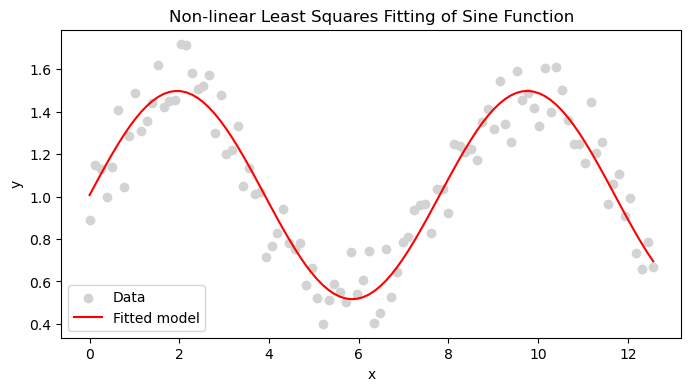

In [85]:
# plot the results
plt.figure(figsize=(8,4))
plt.scatter(x, y, label='Data', color='lightgray')
plt.plot(x, model(x, *params), color='red', label='Fitted model')
plt.title('Non-linear Least Squares Fitting of Sine Function')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()